# Exercise 1 — CIFAR-10 classification with an MLP
## 1. Inspect the training data

100%|██████████| 170M/170M [38:19<00:00, 74.2kB/s]


Training images: 50000
Class: frog


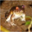

In [ ]:
from torchvision.datasets import CIFAR10

train_data = CIFAR10(root="./data", train=True, download=True)
print("Training images:", len(train_data))

image, label = train_data[0]
print("Class:", train_data.classes[label])
display(image)

## 2. Create the training and validation split

In [3]:
import torch
from torch.utils.data import random_split

train_set, val_set = random_split(
    train_data,
    [45_000, 5_000],
    generator=torch.Generator().manual_seed(42),
)

print("Training:", len(train_set))
print("Validation:", len(val_set))

Training: 45000
Validation: 5000


In [4]:
import json

split = {
    "seed": 42,
    "train_indices": train_set.indices,
    "val_indices": val_set.indices,
}

with open("cifar10_split.json", "w") as file:
    json.dump(split, file)

print("Saved cifar10_split.json")

Saved cifar10_split.json


## 3. Prepare an image for the MLP

In [11]:
from torchvision.transforms import ToTensor

image, label = train_data[0]
image_tensor = ToTensor()(image)
flat_image = image_tensor.flatten()

print("Class:", train_data.classes[label])
print("Tensor shape:", image_tensor.shape)
print("Data type:", image_tensor.dtype)
print("Flattened shape:", flat_image.shape)

Class: frog
Tensor shape: torch.Size([3, 32, 32])
Data type: torch.float32
Flattened shape: torch.Size([3072])


## 4. Create the training and validation data loaders

In [12]:
from torch.utils.data import DataLoader, Subset

tensor_data = CIFAR10(root="./data", train=True, transform=ToTensor())
train_images = Subset(tensor_data, train_set.indices)
val_images = Subset(tensor_data, val_set.indices)

train_loader = DataLoader(train_images, batch_size=64, shuffle=True)
val_loader = DataLoader(val_images, batch_size=64, shuffle=False)

images, labels = next(iter(train_loader))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Flattened batch:", images.flatten(start_dim=1).shape)

Image batch: torch.Size([64, 3, 32, 32])
Label batch: torch.Size([64])
Flattened batch: torch.Size([64, 3072])


## 5. Define the three-layer MLP

In [14]:
import torch
from torch import nn

model = nn.Sequential(
    nn.Flatten(start_dim=1),  # Keep each image separate in the batch
    nn.Linear(3072, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)

# Run the batch from your previous cell through the model once
with torch.no_grad():
    scores = model(images)

print("Class scores:", scores.shape)
print("Labels:", labels.shape)

Class scores: torch.Size([64, 10])
Labels: torch.Size([64])


## 6. Set up the loss function and optimiser

In [15]:
loss_fn = nn.CrossEntropyLoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.001)

with torch.no_grad():
    initial_loss = loss_fn(scores, labels)

print(f"Loss on the first batch before training: {initial_loss.item():.4f}")

Loss on the first batch before training: 2.3137


## 7. Train and validate the MLP

In [16]:
train_losses = []
val_losses = []

In [21]:
model.train()
train_loss_sum = 0.0

for images, labels in train_loader:
    optimiser.zero_grad()
    scores = model(images)
    loss = loss_fn(scores, labels)
    loss.backward()
    optimiser.step()

    train_loss_sum += loss.item() * labels.size(0)

train_losses.append(train_loss_sum / len(train_loader.dataset))

model.eval()
val_loss_sum = 0.0

with torch.no_grad():
    for images, labels in val_loader:
        scores = model(images)
        loss = loss_fn(scores, labels)
        val_loss_sum += loss.item() * labels.size(0)

val_losses.append(val_loss_sum / len(val_loader.dataset))

print(f"Epoch {len(train_losses)}")
print(f"Training loss:   {train_losses[-1]:.4f}")
print(f"Validation loss: {val_losses[-1]:.4f}")

Epoch 5
Training loss:   1.5046
Validation loss: 1.5864


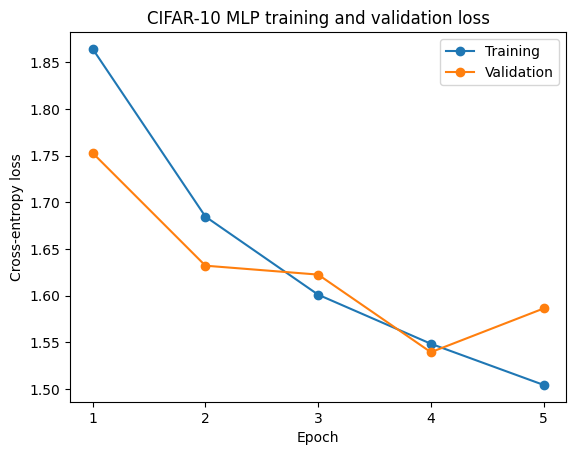

In [22]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.plot(epochs, train_losses, marker="o", label="Training")
plt.plot(epochs, val_losses, marker="o", label="Validation")
plt.xticks(epochs)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("CIFAR-10 MLP training and validation loss")
plt.legend()
plt.show()

In [9]:
# optimiser.zero_grad()
# scores = model(images)
# loss = loss_fn(scores, labels)
# loss.backward()
# optimiser.step()

In [10]:
# with torch.no_grad():
#     updated_loss = loss_fn(model(images), labels)

# print(f"Before the update: {initial_loss.item():.4f}")
# print(f"After the update:  {updated_loss.item():.4f}")

Before the update: 2.3082
After the update:  2.2453


In [23]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in train_loader:
        scores = model(images)
        predictions = scores.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Training accuracy: {correct / total:.2%} ({correct:,}/{total:,})")

Training accuracy: 45.62% (20,529/45,000)


In [24]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        predictions = model(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Validation accuracy: {correct / total:.2%} ({correct:,}/{total:,})")

Validation accuracy: 44.40% (2,220/5,000)


In [25]:
test_data = CIFAR10(root="./data", train=False, transform=ToTensor())
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Test accuracy: {correct / total:.2%} ({correct:,}/{total:,})")

Test accuracy: 44.03% (4,403/10,000)
